# 02 — Toronto urban-form inputs

## Purpose

This notebook prepares the urban-form inputs for the Toronto v2 thermal-accessibility experiment.

The overall study domain is **8 km × 8 km** and was defined in Notebook 01. For urban-form and thermal modelling, the domain is organized into **2 km × 2 km tiles** so that VoxCity and later SOLWEIG runs can be processed in manageable pieces.

This notebook will:

1. load the Toronto study area and walking network from Notebook 01;
2. create or load a reusable 4 × 4 tile grid;
3. retrieve lightweight OSM urban-form context;
4. inspect building and green-space coverage;
5. test VoxCity on a single 2 km × 2 km tile;
6. inspect the resulting building, canopy, land-cover, and terrain grids;
7. save the tile grid and first VoxCity test outputs.

The objective here is **input validation**, not yet full thermal simulation.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
import json

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import xarray as xr

from shapely.geometry import box
from voxcity.generator import get_voxcity

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

for folder in [
    TORONTO_RAW,
    TORONTO_INTERIM,
    TORONTO_OUTPUTS,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility


## 2. Load the study area, campus center, and walking network

These are the outputs created in Notebook 01.

In [2]:
study_area_path = (
    TORONTO_RAW / "toronto_study_area_8km.gpkg"
)

campus_center_path = (
    TORONTO_RAW / "toronto_uoft_center.gpkg"
)

walking_graph_path = (
    TORONTO_RAW / "toronto_walk_8km.graphml"
)

study_area = gpd.read_file(
    study_area_path
)

campus_center = gpd.read_file(
    campus_center_path
)

G_walk = ox.load_graphml(
    walking_graph_path
)

walk_nodes, walk_edges = ox.graph_to_gdfs(
    G_walk
)

print("Study area CRS:", study_area.crs)
print("Study area area (km²):", study_area.geometry.area.iloc[0] / 1_000_000)
print("Walking nodes:", G_walk.number_of_nodes())
print("Walking edges:", G_walk.number_of_edges())

Study area CRS: EPSG:32617
Study area area (km²): 64.0
Walking nodes: 35817
Walking edges: 96924


## 3. Build the reusable 2 km × 2 km tile grid

The 8 km × 8 km domain is divided into **16 tiles**.

The same tile grid will later be reused for:

- VoxCity processing;
- Toronto building-height enrichment;
- SOLWEIG simulation;
- thermal-raster mosaicking.

In [3]:
TARGET_CRS = study_area.crs
TILE_SIZE_M = 2000

xmin, ymin, xmax, ymax = study_area.total_bounds

tile_records = []
tile_number = 1

for row in range(4):
    for col in range(4):

        tile_xmin = xmin + col * TILE_SIZE_M
        tile_xmax = tile_xmin + TILE_SIZE_M

        tile_ymin = ymin + row * TILE_SIZE_M
        tile_ymax = tile_ymin + TILE_SIZE_M

        tile_records.append({
            "tile_id": f"T{tile_number:02d}",
            "row": row + 1,
            "col": col + 1,
            "geometry": box(
                tile_xmin,
                tile_ymin,
                tile_xmax,
                tile_ymax,
            ),
        })

        tile_number += 1

tiles = gpd.GeoDataFrame(
    tile_records,
    crs=TARGET_CRS,
)

tiles["area_km2"] = (
    tiles.geometry.area / 1_000_000
)

print("Number of tiles:", len(tiles))
print("Total tile area:", tiles["area_km2"].sum(), "km²")

display(
    tiles[
        ["tile_id", "row", "col", "area_km2"]
    ]
)

Number of tiles: 16
Total tile area: 64.0 km²


,tile_id,row,col,area_km2
0,T01,1,1,4.0
1,T02,1,2,4.0
2,T03,1,3,4.0
3,T04,1,4,4.0
4,T05,2,1,4.0
5,T06,2,2,4.0
6,T07,2,3,4.0
7,T08,2,4,4.0
8,T09,3,1,4.0
9,T10,3,2,4.0


## 4. Identify the U of T tile

We use the tile containing the campus center as the first VoxCity test tile.

This gives us a central urban tile with dense built form and a known spatial reference.

In [5]:
# --------------------------------------------------
# Create a 2 km × 2 km VoxCity pilot tile
# centered directly on U of T
# --------------------------------------------------

PILOT_HALF_WIDTH_M = 1000

campus_x = campus_center.geometry.x.iloc[0]
campus_y = campus_center.geometry.y.iloc[0]

pilot_geometry = box(
    campus_x - PILOT_HALF_WIDTH_M,
    campus_y - PILOT_HALF_WIDTH_M,
    campus_x + PILOT_HALF_WIDTH_M,
    campus_y + PILOT_HALF_WIDTH_M,
)

test_tile = gpd.GeoDataFrame(
    {
        "tile_id": ["UOFT_PILOT"],
        "description": [
            "2 km × 2 km pilot tile centered on U of T"
        ],
    },
    geometry=[pilot_geometry],
    crs=TARGET_CRS,
)

TEST_TILE_ID = "UOFT_PILOT"

print("Pilot tile:", TEST_TILE_ID)
print(
    "Area:",
    test_tile.geometry.area.iloc[0] / 1_000_000,
    "km²"
)

display(test_tile)

Pilot tile: UOFT_PILOT
Area: 4.0 km²


,tile_id,description,geometry
0,UOFT_PILOT,2 km × 2 km pilot tile centered on U of T,"POLYGON ((630323.607 4834772.969, 630323.607 4..."


## 5. Visualize the full tile grid and test tile

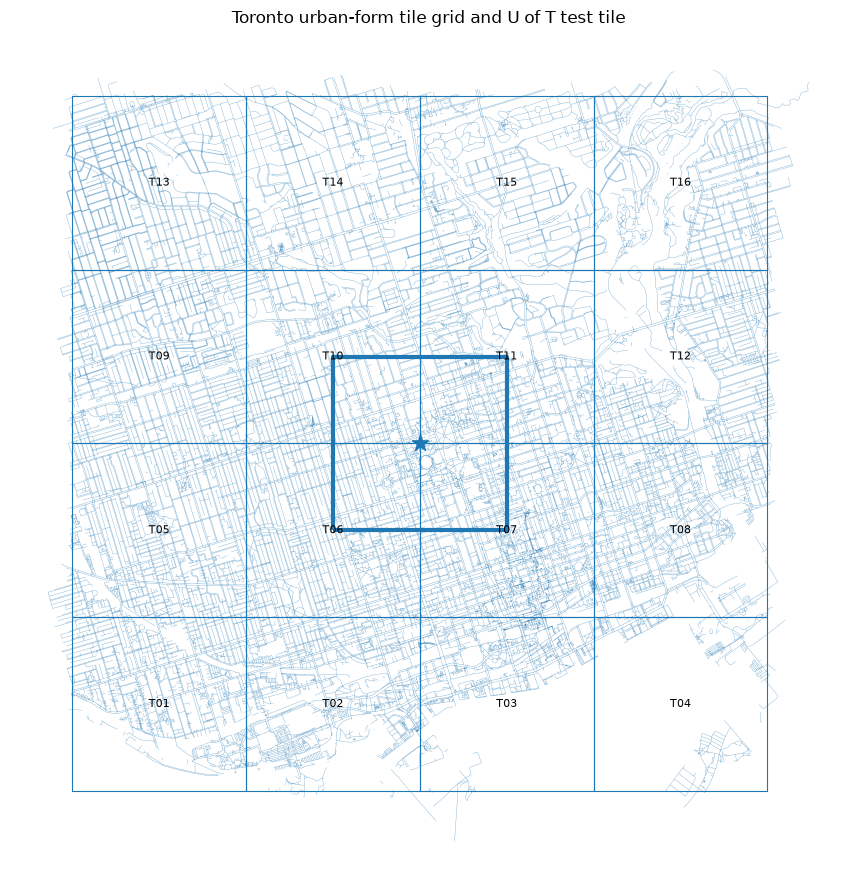

In [6]:
fig, ax = plt.subplots(figsize=(9, 9))

walk_edges.plot(
    ax=ax,
    linewidth=0.25,
    alpha=0.35,
)

tiles.boundary.plot(
    ax=ax,
    linewidth=0.8,
)

test_tile.boundary.plot(
    ax=ax,
    linewidth=3.0,
)

campus_center.plot(
    ax=ax,
    marker="*",
    markersize=150,
    zorder=10,
)

for _, row in tiles.iterrows():
    point = row.geometry.centroid

    ax.text(
        point.x,
        point.y,
        row["tile_id"],
        ha="center",
        va="center",
        fontsize=8,
    )

ax.set_title(
    "Toronto urban-form tile grid and U of T test tile"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 6. Save the tile grid

This makes the tile definitions reusable across the rest of the Toronto workflow.

In [7]:
tile_grid_path = (
    TORONTO_RAW / "toronto_study_tiles_2km.gpkg"
)

tiles.to_file(
    tile_grid_path,
    driver="GPKG",
)

print("Saved:", tile_grid_path)

2026-10-16 01:24:20,814 - INFO - Created 16 records


Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/toronto_study_tiles_2km.gpkg


## 7. Retrieve lightweight OSM urban-form context for the full domain

This step is only for inspection and quality control.

We retrieve:

- building footprints;
- parks and gardens;
- grass and recreation areas.

These layers are **not yet the final thermal inputs**. Later notebooks can replace or enrich them with Toronto-specific municipal datasets.

In [8]:
study_area_wgs84 = study_area.to_crs(4326)

study_polygon_wgs84 = (
    study_area_wgs84.geometry.iloc[0]
)

urban_tags = {
    "building": True,
    "leisure": [
        "park",
        "garden",
    ],
    "landuse": [
        "grass",
        "recreation_ground",
    ],
}

urban_context = ox.features_from_polygon(
    study_polygon_wgs84,
    tags=urban_tags,
)

urban_context = (
    urban_context
    .reset_index()
    .to_crs(TARGET_CRS)
)

print("OSM urban-form features:", len(urban_context))
print()
print(
    urban_context.geometry.geom_type.value_counts()
)

OSM urban-form features: 66784

Polygon         66717
Point              46
MultiPolygon       21
Name: count, dtype: int64


## 8. Separate building and green-space context

In [9]:
building_series = urban_context.get(
    "building",
    pd.Series(
        index=urban_context.index,
        dtype=object,
    ),
)

leisure_series = urban_context.get(
    "leisure",
    pd.Series(
        index=urban_context.index,
        dtype=object,
    ),
)

landuse_series = urban_context.get(
    "landuse",
    pd.Series(
        index=urban_context.index,
        dtype=object,
    ),
)

building_context = urban_context[
    building_series.notna()
].copy()

green_context = urban_context[
    leisure_series.isin(
        ["park", "garden"]
    )
    |
    landuse_series.isin(
        ["grass", "recreation_ground"]
    )
].copy()

print("Building features:", len(building_context))
print("Green-space features:", len(green_context))

Building features: 60997
Green-space features: 5787


## 9. Visualize OSM urban-form context

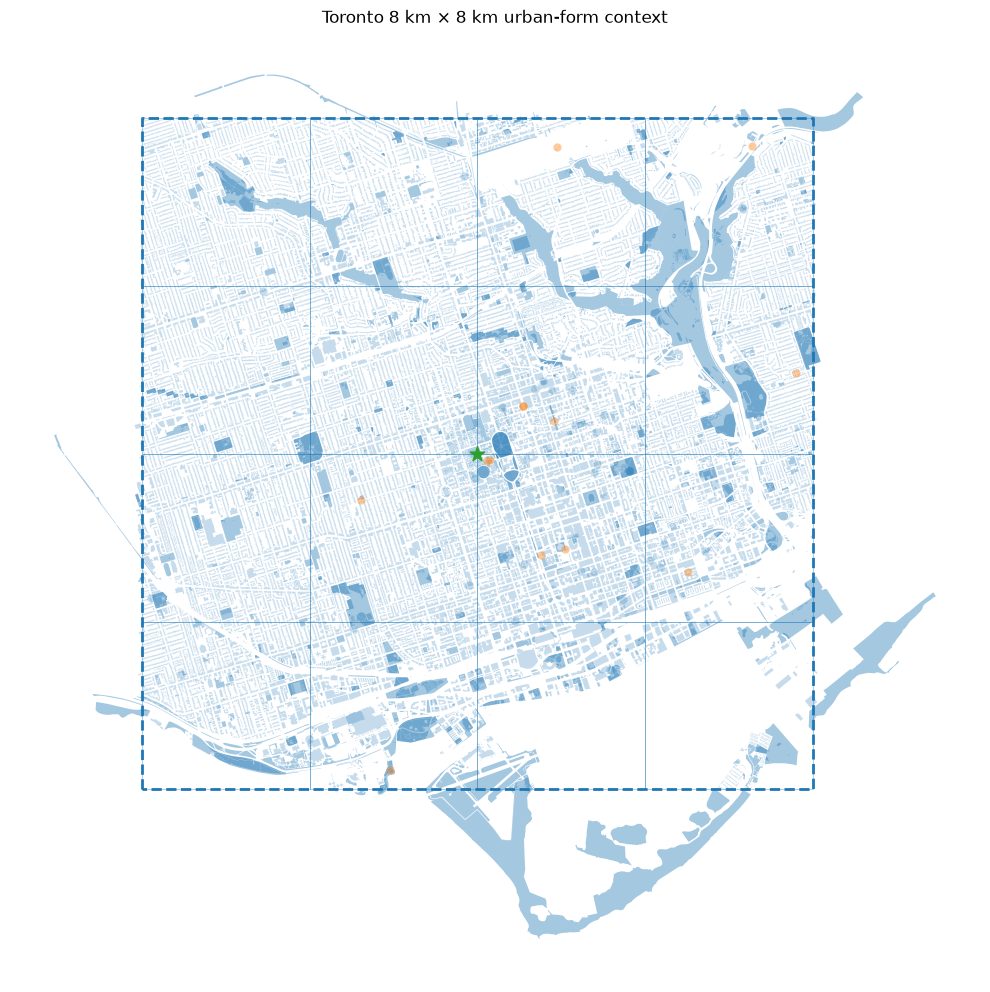

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))

if len(building_context):
    building_context.plot(
        ax=ax,
        alpha=0.25,
        linewidth=0,
    )

if len(green_context):
    green_context.plot(
        ax=ax,
        alpha=0.40,
        linewidth=0,
    )

study_area.boundary.plot(
    ax=ax,
    linewidth=2.0,
    linestyle="--",
)

tiles.boundary.plot(
    ax=ax,
    linewidth=0.5,
    alpha=0.5,
)

campus_center.plot(
    ax=ax,
    marker="*",
    markersize=120,
    zorder=10,
)

ax.set_title(
    "Toronto 8 km × 8 km urban-form context"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 10. Prepare the U of T test tile for VoxCity

VoxCity expects a rectangular set of longitude/latitude vertices.

The tile is therefore converted to WGS84 and its bounding coordinates are extracted.

In [11]:
test_tile_wgs84 = test_tile.to_crs(4326)

minlon, minlat, maxlon, maxlat = (
    test_tile_wgs84.total_bounds
)

rectangle_vertices = [
    (minlon, minlat),
    (minlon, maxlat),
    (maxlon, maxlat),
    (maxlon, minlat),
]

print("Test tile:", TEST_TILE_ID)
print("Rectangle vertices:")
for vertex in rectangle_vertices:
    print(vertex)

Test tile: UOFT_PILOT
Rectangle vertices:
(np.float64(-79.40864362272377), np.float64(43.65453519234437))
(np.float64(-79.40864362272377), np.float64(43.67288422832106))
(np.float64(-79.38336793360907), np.float64(43.67288422832106))
(np.float64(-79.38336793360907), np.float64(43.65453519234437))


## 11. Run VoxCity on the single test tile

The first test uses a **5 m mesh**, matching the Sevilla PoC resolution.

A 2 km × 2 km tile at 5 m resolution is approximately:

\[
400 \times 400 = 160{,}000
\]

horizontal cells before accounting for exact reprojection dimensions.

This is deliberately much smaller than voxelizing the full 64 km² domain at once.

INFO | voxcity.voxcity.generator.api | Auto-selecting data sources for: building_source, land_cover_source, canopy_height_source, dem_source, building_complementary_source


Loading formatted geocoded file...


INFO | voxcity.voxcity.generator.api | Detected country for ROI center (-79.3960, 43.6637): Canada
INFO | voxcity.voxcity.generator.api | Selected data sources:
INFO | voxcity.voxcity.generator.api | - Buildings(base)=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Buildings(comp)=Microsoft Building Footprints | https://github.com/microsoft/GlobalMLBuildingFootprints
INFO | voxcity.voxcity.generator.api | - LandCover=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Canopy=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - DEM=Flat
INFO | voxcity.voxcity.generator.api | - ComplementHeight=10



  • Land Cover:  OpenStreetMap
  • Building:    OpenStreetMap
  • Canopy:      OpenStreetMap
  • DEM:         Flat
------------------------------------------------------------
Downloading... (this may take a moment)
  ✓ Dem complete (1/4)
Fetching data from Overpass API...
  Downloaded 2141 individual trees and 5 tree polygons from OSM
  Downloaded 2146 trees from OSM
  Created canopy grids: (408, 408)
  ✓ Canopy complete (2/4)
Converting data to GeoJSON format...


INFO | voxcity.voxcity.downloader.utils | File downloaded successfully and saved as output/dataset-links.csv
INFO | voxcity.voxcity.downloader.utils | File downloaded successfully and saved as output/Canada_030223131.gz
INFO | voxcity.voxcity.geoprocessor.raster.buildings | 2649 of the total 5561 building footprint from the base data source did not have height data.
INFO | voxcity.voxcity.geoprocessor.heights | For 2404 of these building footprints without height, values from the complementary source were assigned.
INFO | voxcity.voxcity.geoprocessor.heights | For 245 of these building footprints without height, no data exist in complementary data.


  ✓ Building complete (3/4)
  ✓ Land Cover complete (4/4)
------------------------------------------------------------
All downloads complete!



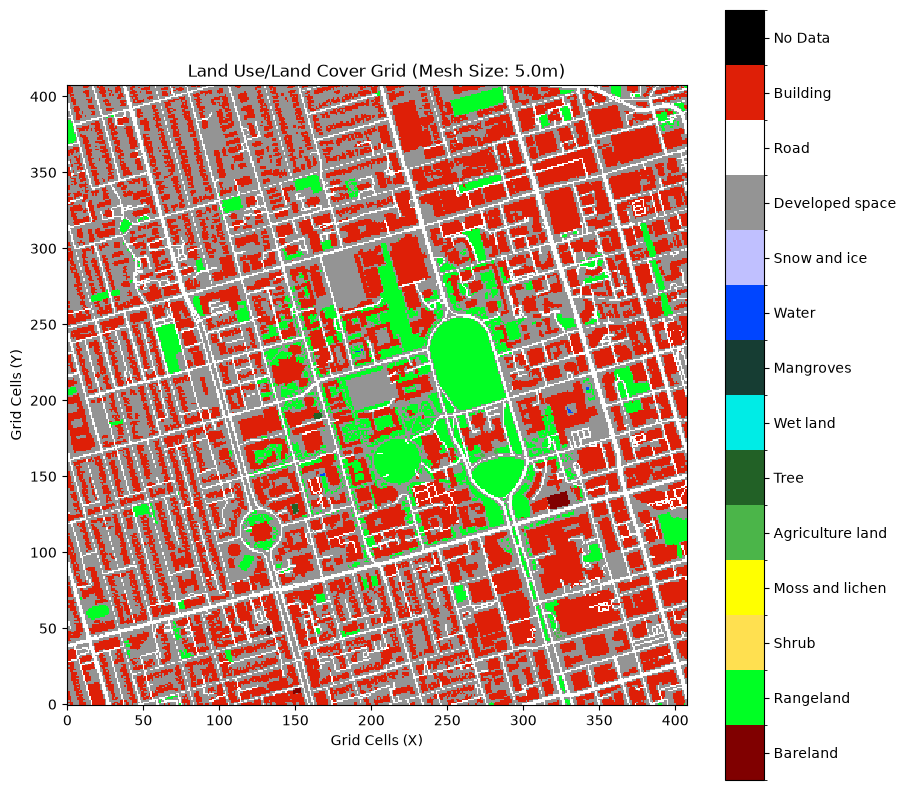

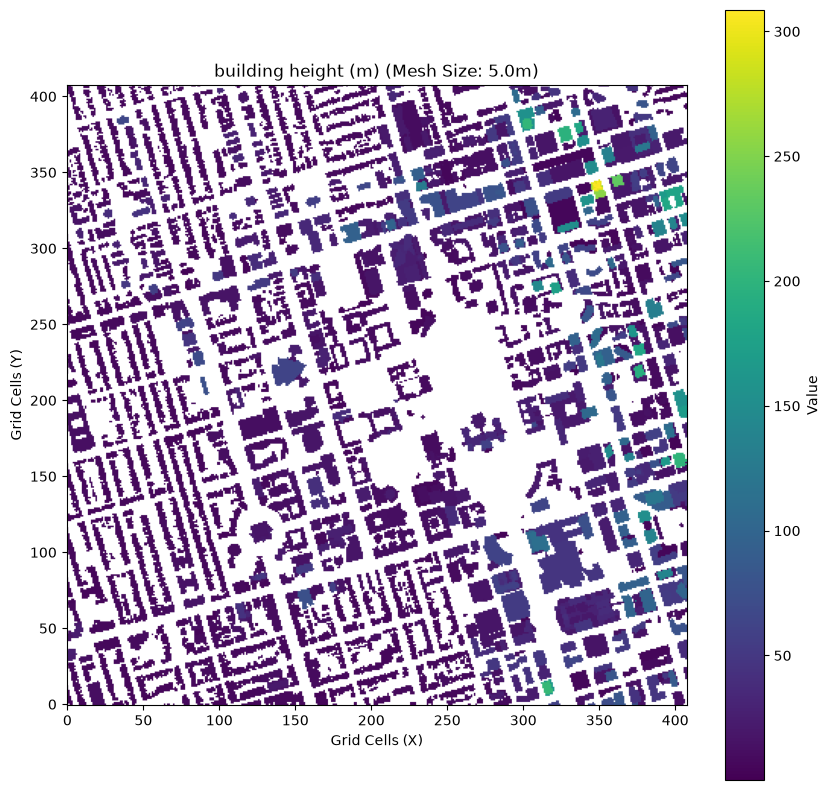

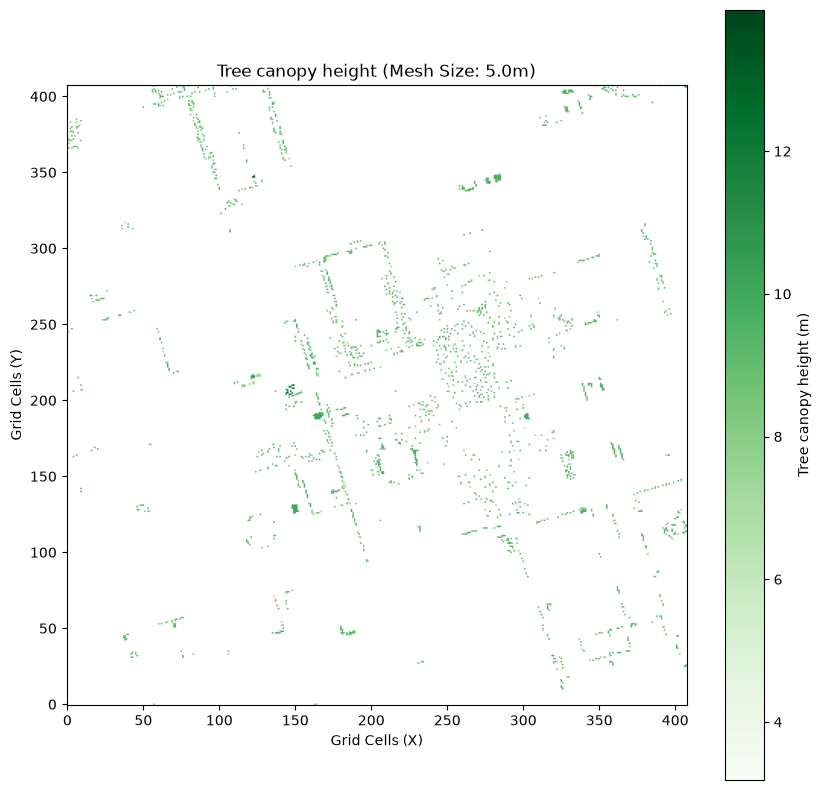

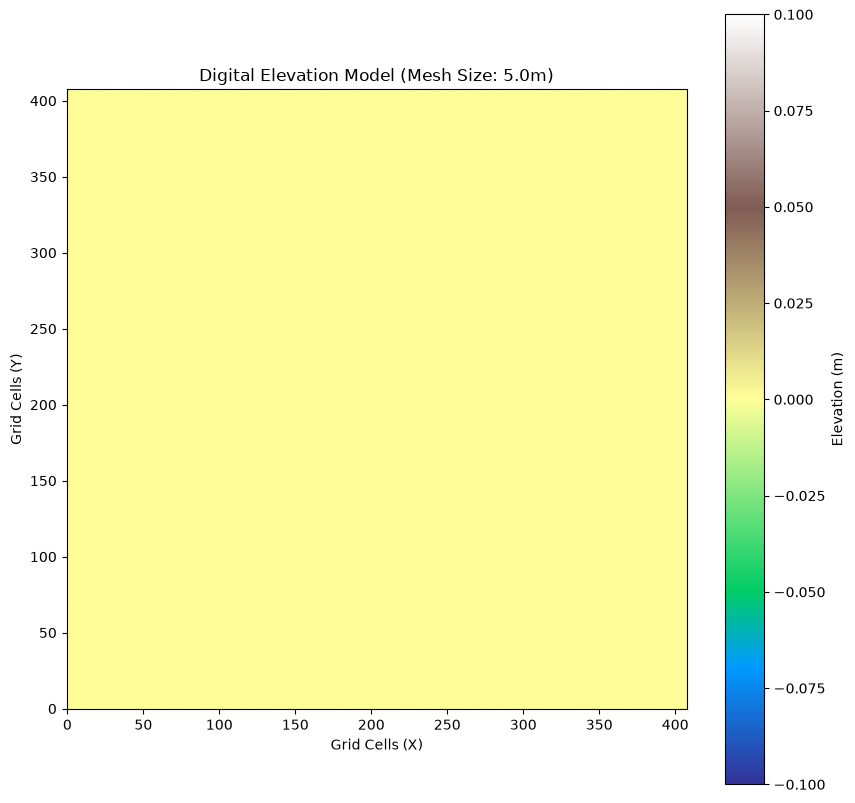

INFO | voxcity.voxcity.generator.voxelizer | Generating 3D voxel data
INFO | voxcity.voxcity.generator.voxelizer | 
Voxel Grid Semantic Codes:
  -3 : Building volume
  -2 : Tree canopy (vegetation)
  -1 : Ground/Subsurface
  >=1: Land cover class at ground surface (see Land Cover Classes)

INFO | voxcity.voxcity.generator.voxelizer | 
VoxCity Standard Land Cover Classes (1-based indices, used in voxel grids):
--------------------------------------------------
   1: Bareland           - Bare soil, rocks, desert
   2: Rangeland          - Grassland, pasture
   3: Shrub              - Shrubland, bushes
   4: Agriculture land   - Cropland, farmland
   5: Tree               - Forest, tree cover
   6: Moss and lichen    - Moss, lichen cover
   7: Wet land           - Wetland, marsh
   8: Mangrove           - Mangrove forest
   9: Water              - Water bodies
  10: Snow and ice       - Snow, ice, glaciers
  11: Developed space    - Urban areas, parking
  12: Road               - Roads, p

VoxCity results saved to output/voxcity.h5
✓ VoxCity test tile created.


In [12]:
VOXCITY_MESH_M = 5

voxcity_test = get_voxcity(
    rectangle_vertices,
    meshsize=VOXCITY_MESH_M,
)

print("✓ VoxCity test tile created.")

## 12. Inspect the VoxCity object

We examine the main urban-form components that will matter later for thermal modelling.

In [13]:
print("VoxCity object:", type(voxcity_test))
print()

print("Building height shape:")
print(voxcity_test.buildings.heights.shape)

print("\nCanopy-top shape:")
print(voxcity_test.tree_canopy.top.shape)

print("\nLand-cover shape:")
print(voxcity_test.land_cover.classes.shape)

print("\nDEM shape:")
print(voxcity_test.dem.elevation.shape)

VoxCity object: <class 'voxcity.models.VoxCity'>

Building height shape:
(408, 408)

Canopy-top shape:
(408, 408)

Land-cover shape:
(408, 408)

DEM shape:
(408, 408)


## 13. Inspect baseline building information

This step is important because VoxCity may assign default building heights when a detailed height source is unavailable.

Later, Toronto-specific 3D building data can be used to improve these heights.

In [14]:
building_gdf = (
    voxcity_test.extras["building_gdf"]
    .copy()
)

print("VoxCity building records:", len(building_gdf))

if "height" in building_gdf.columns:
    print("\nBuilding height summary:")
    display(
        building_gdf["height"].describe()
    )

if "height_source" in building_gdf.columns:
    print("\nHeight-source counts:")
    display(
        building_gdf[
            "height_source"
        ].value_counts(
            dropna=False
        )
    )

VoxCity building records: 5561

Building height summary:


count    5561.000000
mean       20.189989
std        32.695597
min         0.100000
25%         6.925358
50%         9.000000
75%        17.500000
max       308.600000
Name: height, dtype: float64


Height-source counts:


height_source
default     2649
levels      2034
explicit     878
Name: count, dtype: int64

## 14. Inspect vegetation information

In [15]:
tree_gdf = (
    voxcity_test.extras["tree_gdf"]
    .copy()
)

print("VoxCity tree records:", len(tree_gdf))

print("\nGeometry types:")
display(
    tree_gdf.geometry.geom_type.value_counts()
)

tree_columns = [
    column
    for column in [
        "top_height",
        "bottom_height",
        "crown_diameter",
    ]
    if column in tree_gdf.columns
]

if tree_columns:
    display(
        tree_gdf[
            tree_columns
        ].describe()
    )

VoxCity tree records: 2146

Geometry types:


Point      2141
Polygon       5
Name: count, dtype: int64

,top_height,bottom_height,crown_diameter
count,2146.000000,2146.000000,2146.000000
mean,9.893616,3.955955,5.964177
std,0.865447,0.324407,0.703359
min,1.700000,0.680000,0.000000
25%,10.000000,4.000000,6.000000
50%,10.000000,4.000000,6.000000
75%,10.000000,4.000000,6.000000
max,15.000000,4.000000,14.323957


## 15. Visualize the gridded urban-form layers

These plots provide the first visual check of the Toronto VoxCity output.

The objective is to verify that buildings, vegetation, land cover, and terrain appear spatially plausible before scaling the process to all tiles.

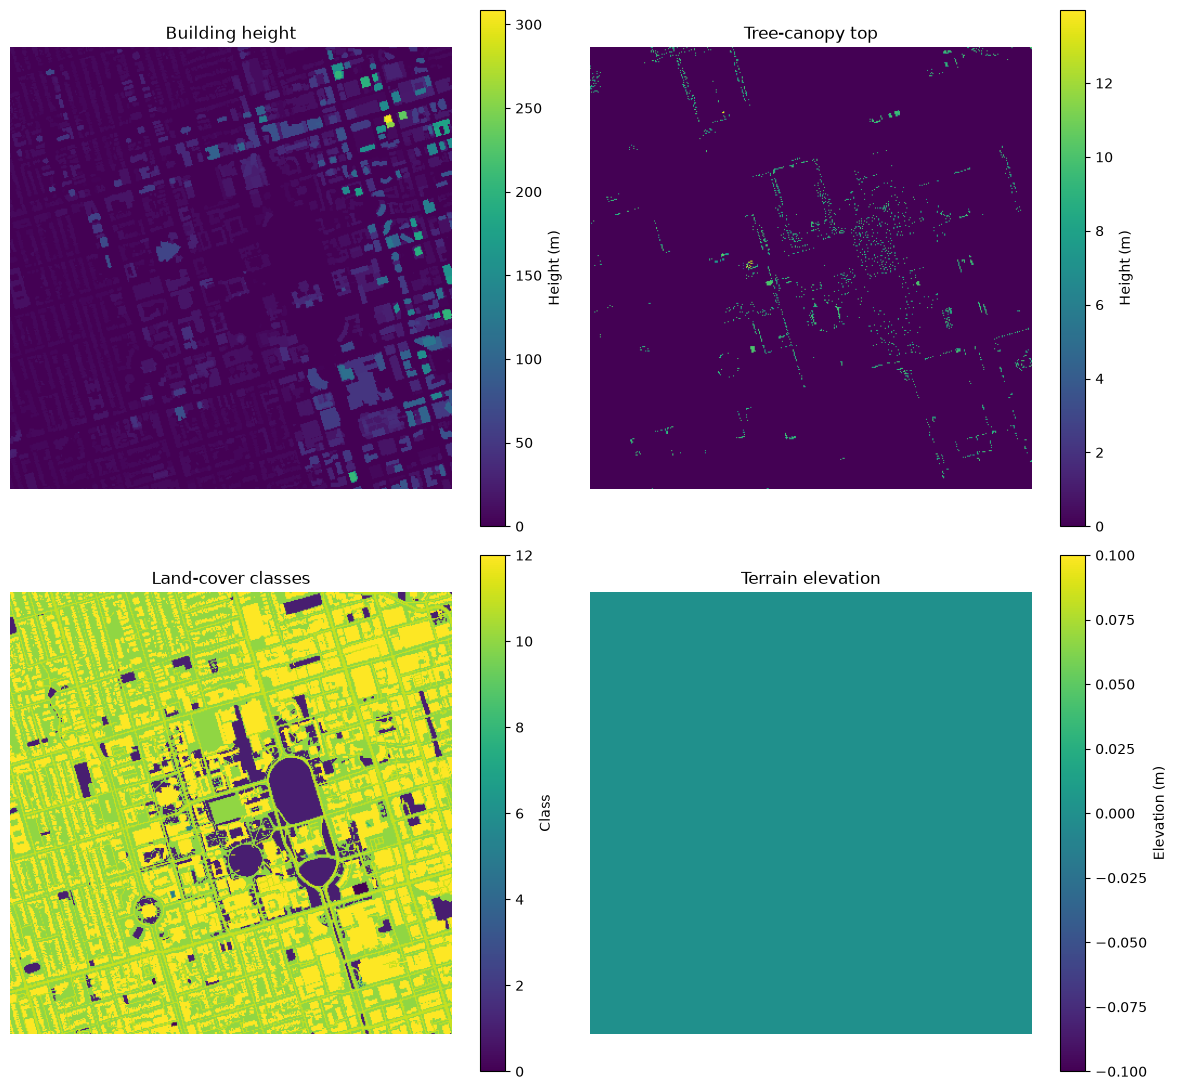

In [16]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 11),
)

image0 = axes[0, 0].imshow(
    voxcity_test.buildings.heights,
    origin="lower",
)

axes[0, 0].set_title(
    "Building height"
)

plt.colorbar(
    image0,
    ax=axes[0, 0],
    label="Height (m)",
)


image1 = axes[0, 1].imshow(
    voxcity_test.tree_canopy.top,
    origin="lower",
)

axes[0, 1].set_title(
    "Tree-canopy top"
)

plt.colorbar(
    image1,
    ax=axes[0, 1],
    label="Height (m)",
)


image2 = axes[1, 0].imshow(
    voxcity_test.land_cover.classes,
    origin="lower",
)

axes[1, 0].set_title(
    "Land-cover classes"
)

plt.colorbar(
    image2,
    ax=axes[1, 0],
    label="Class",
)


image3 = axes[1, 1].imshow(
    voxcity_test.dem.elevation,
    origin="lower",
)

axes[1, 1].set_title(
    "Terrain elevation"
)

plt.colorbar(
    image3,
    ax=axes[1, 1],
    label="Elevation (m)",
)

for ax in axes.ravel():
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 16. Summarize grid coverage

These simple diagnostics help identify empty or suspiciously uniform layers.

In [17]:
building_grid = (
    voxcity_test.buildings.heights
)

canopy_grid = (
    voxcity_test.tree_canopy.top
)

dem_grid = (
    voxcity_test.dem.elevation
)

diagnostics = pd.DataFrame(
    {
        "layer": [
            "Building height",
            "Canopy top",
            "DEM",
        ],
        "nonzero_cells": [
            int(
                np.count_nonzero(
                    np.nan_to_num(
                        building_grid
                    )
                )
            ),
            int(
                np.count_nonzero(
                    np.nan_to_num(
                        canopy_grid
                    )
                )
            ),
            int(
                np.count_nonzero(
                    np.nan_to_num(
                        dem_grid
                    )
                )
            ),
        ],
        "min": [
            float(
                np.nanmin(
                    building_grid
                )
            ),
            float(
                np.nanmin(
                    canopy_grid
                )
            ),
            float(
                np.nanmin(
                    dem_grid
                )
            ),
        ],
        "mean": [
            float(
                np.nanmean(
                    building_grid
                )
            ),
            float(
                np.nanmean(
                    canopy_grid
                )
            ),
            float(
                np.nanmean(
                    dem_grid
                )
            ),
        ],
        "max": [
            float(
                np.nanmax(
                    building_grid
                )
            ),
            float(
                np.nanmax(
                    canopy_grid
                )
            ),
            float(
                np.nanmax(
                    dem_grid
                )
            ),
        ],
    }
)

display(diagnostics)

,layer,nonzero_cells,min,mean,max
0,Building height,68489,0.0,10.544304,308.600000
1,Canopy top,2414,0.0,0.131120,13.978205
2,DEM,0,0.0,0.000000,0.000000


## 17. Save the single-tile VoxCity test outputs

We save both the vector inputs and an xarray/NetCDF representation of the first tile.

These outputs are only the **baseline VoxCity test**, not yet the final Toronto thermal inputs.

In [18]:
test_output_dir = (
    TORONTO_INTERIM
    / "voxcity_test"
)

test_output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

building_gdf.to_file(
    test_output_dir
    / f"{TEST_TILE_ID}_buildings_voxcity.gpkg",
    driver="GPKG",
)

tree_gdf.to_file(
    test_output_dir
    / f"{TEST_TILE_ID}_trees_voxcity.gpkg",
    driver="GPKG",
)

test_ds = (
    voxcity_test.to_xarray()
)

test_ds_to_save = (
    test_ds.copy()
)

if "rectangle_vertices" in test_ds_to_save.attrs:
    test_ds_to_save.attrs[
        "rectangle_vertices"
    ] = json.dumps(
        np.asarray(
            test_ds_to_save.attrs[
                "rectangle_vertices"
            ]
        ).tolist()
    )

test_ds_to_save.to_netcdf(
    test_output_dir
    / f"{TEST_TILE_ID}_voxcity_initial.nc"
)

print(
    "Saved VoxCity test outputs to:",
    test_output_dir,
)

2026-10-16 01:27:30,280 - INFO - Created 5,561 records
2026-10-16 01:27:30,329 - INFO - Created 2,146 records


Saved VoxCity test outputs to: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_test


## 18. What to inspect before scaling to all tiles

Before generating VoxCity data for all sixteen tiles, check:

1. **building coverage** — are most expected buildings represented?
2. **building heights** — how many are defaults versus observed/estimated values?
3. **vegetation coverage** — are tree/canopy data sufficiently dense?
4. **land cover** — do parks, roads, and built surfaces appear reasonable?
5. **terrain** — is the DEM plausible and spatially variable?
6. **runtime** — is one 2 km × 2 km tile computationally manageable?

The answers determine whether the next notebook should:

- directly process all tiles with VoxCity; or
- first enrich Toronto building heights and vegetation from municipal datasets.

## Interpretation and next step

This notebook intentionally stops after a **single-tile VoxCity test**.

That is useful because Toronto provides richer municipal urban-form data than the Sevilla PoC. Before scaling VoxCity to 64 km², the next methodological decision should be whether to replace or enrich baseline VoxCity inputs with Toronto-specific building-height and canopy datasets.

The likely next notebook is:

**`03_toronto_building_height_enrichment.ipynb`**

followed by a tiled full-domain VoxCity preparation stage.